<a href="https://colab.research.google.com/github/syambudi14/Syam_Budi_Luthfi_Tugas_Basis_Data./blob/main/Syam_Budi_Luthfi_Tugas_Basis_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Membuat koneksi ke database SQLite (file akan tersimpan sementara di session Colab)
conn = sqlite3.connect('perpustakaan.db')
cursor = conn.cursor()

# Membuat Tabel Buku
cursor.execute('''
CREATE TABLE IF NOT EXISTS buku (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    judul TEXT,
    penulis TEXT,
    tahun INTEGER
)
''')

# Membuat Tabel Anggota
cursor.execute('''
CREATE TABLE IF NOT EXISTS anggota (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    nama TEXT,
    email TEXT
)
''')

# Membuat Tabel Peminjaman
cursor.execute('''
CREATE TABLE IF NOT EXISTS peminjaman (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    id_anggota INTEGER,
    id_buku INTEGER,
    tgl_pinjam DATE,
    tgl_kembali DATE,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id)
)
''')

conn.commit()
print("Berhasil: Database dan tabel berhasil dibuat!")

Berhasil: Database dan tabel berhasil dibuat!


In [2]:
# 1a. Menambahkan 5 data buku
buku_data = [
    ('Pemrograman Python untuk Pemula', 'Budi Raharjo', 2021),
    ('Machine Learning Terapan', 'Siti Aminah', 2022),
    ('Sistem Basis Data Lanjut', 'C.J. Date', 2019),
    ('Algoritma dan Struktur Data', 'Andi Susanto', 2020),
    ('Jaringan Komputer', 'Rina Wati', 2023)
]
cursor.executemany('INSERT INTO buku (judul, penulis, tahun) VALUES (?, ?, ?)', buku_data)

# 1a. Menambahkan 3 data anggota (Saya masukkan nama Anda sebagai salah satu anggota)
anggota_data = [
    ('Syam Budi Luthfi', 'syam.budi@email.com'),
    ('Ahmad Fauzi', 'ahmad@email.com'),
    ('Dewi Lestari', 'dewi@email.com')
]
cursor.executemany('INSERT INTO anggota (nama, email) VALUES (?, ?)', anggota_data)

# 1b. Menambahkan 4 transaksi peminjaman (1 belum dikembalikan / NULL)
peminjaman_data = [
    (1, 1, '2024-05-01', '2024-05-08'), # Syam pinjam buku 1 (dikembalikan)
    (2, 2, '2024-05-10', '2024-05-15'), # Ahmad pinjam buku 2 (dikembalikan)
    (3, 4, '2024-05-12', '2024-05-20'), # Dewi pinjam buku 4 (dikembalikan)
    (1, 3, '2024-05-25', None)          # Syam pinjam buku 3 (BELUM dikembalikan/NULL)
]
cursor.executemany('INSERT INTO peminjaman (id_anggota, id_buku, tgl_pinjam, tgl_kembali) VALUES (?, ?, ?, ?)', peminjaman_data)

conn.commit()
print("Berhasil: Data buku, anggota, dan peminjaman telah diinput.")

Berhasil: Data buku, anggota, dan peminjaman telah diinput.


In [3]:
# 1c. Tampilkan daftar peminjaman lengkap (JOIN)
query_join = '''
SELECT p.id as ID_Pinjam, a.nama as Nama_Anggota, b.judul as Judul_Buku, p.tgl_pinjam, p.tgl_kembali
FROM peminjaman p
JOIN anggota a ON p.id_anggota = a.id
JOIN buku b ON p.id_buku = b.id
'''
df_peminjaman = pd.read_sql_query(query_join, conn)
print("--- Daftar Peminjaman Lengkap (1c) ---")
display(df_peminjaman)

# 1d. Hitung jumlah total buku dipinjam per anggota (GROUP BY)
query_groupby = '''
SELECT a.nama as Nama_Anggota, COUNT(p.id_buku) as Total_Buku_Dipinjam
FROM anggota a
LEFT JOIN peminjaman p ON a.id = p.id_anggota
GROUP BY a.id, a.nama
'''
df_agregasi = pd.read_sql_query(query_groupby, conn)
print("\n--- Jumlah Buku Dipinjam Per Anggota (1d) ---")
display(df_agregasi)

--- Daftar Peminjaman Lengkap (1c) ---


,ID_Pinjam,Nama_Anggota,Judul_Buku,tgl_pinjam,tgl_kembali
0,1,Syam Budi Luthfi,Pemrograman Python untuk Pemula,2024-05-01,2024-05-08
1,2,Ahmad Fauzi,Machine Learning Terapan,2024-05-10,2024-05-15
2,3,Dewi Lestari,Algoritma dan Struktur Data,2024-05-12,2024-05-20
3,4,Syam Budi Luthfi,Sistem Basis Data Lanjut,2024-05-25,None



--- Jumlah Buku Dipinjam Per Anggota (1d) ---


,Nama_Anggota,Total_Buku_Dipinjam
0,Syam Budi Luthfi,2
1,Ahmad Fauzi,1
2,Dewi Lestari,1


In [4]:
# 2a & 2b. Eksplorasi Data: Menghitung Durasi Peminjaman (Dalam Hari)

# Konversi kolom teks menjadi tipe datetime pandas
df_peminjaman['tgl_pinjam'] = pd.to_datetime(df_peminjaman['tgl_pinjam'])
df_peminjaman['tgl_kembali'] = pd.to_datetime(df_peminjaman['tgl_kembali'])

# Hitung durasi peminjaman.
# Catatan: Yang belum dikembalikan (NaT) akan bernilai NaN (Not a Number)
df_peminjaman['Durasi_Hari'] = (df_peminjaman['tgl_kembali'] - df_peminjaman['tgl_pinjam']).dt.days

print("--- Hasil Eksplorasi Data (Durasi Peminjaman) ---")
display(df_peminjaman)

# Mengidentifikasi pola sederhana:
belum_kembali = df_peminjaman['tgl_kembali'].isna().sum()
rata_durasi = df_peminjaman['Durasi_Hari'].mean()
print(f"\nInsight: Terdapat {belum_kembali} buku yang belum dikembalikan.")
print(f"Insight: Rata-rata durasi peminjaman buku yang sudah dikembalikan adalah {rata_durasi:.1f} hari.")

--- Hasil Eksplorasi Data (Durasi Peminjaman) ---


,ID_Pinjam,Nama_Anggota,Judul_Buku,tgl_pinjam,tgl_kembali,Durasi_Hari
0,1,Syam Budi Luthfi,Pemrograman Python untuk Pemula,2024-05-01,2024-05-08,7.0
1,2,Ahmad Fauzi,Machine Learning Terapan,2024-05-10,2024-05-15,5.0
2,3,Dewi Lestari,Algoritma dan Struktur Data,2024-05-12,2024-05-20,8.0
3,4,Syam Budi Luthfi,Sistem Basis Data Lanjut,2024-05-25,NaT,NaN



Insight: Terdapat 1 buku yang belum dikembalikan.
Insight: Rata-rata durasi peminjaman buku yang sudah dikembalikan adalah 6.7 hari.


/tmp/ipykernel_370/23046942.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


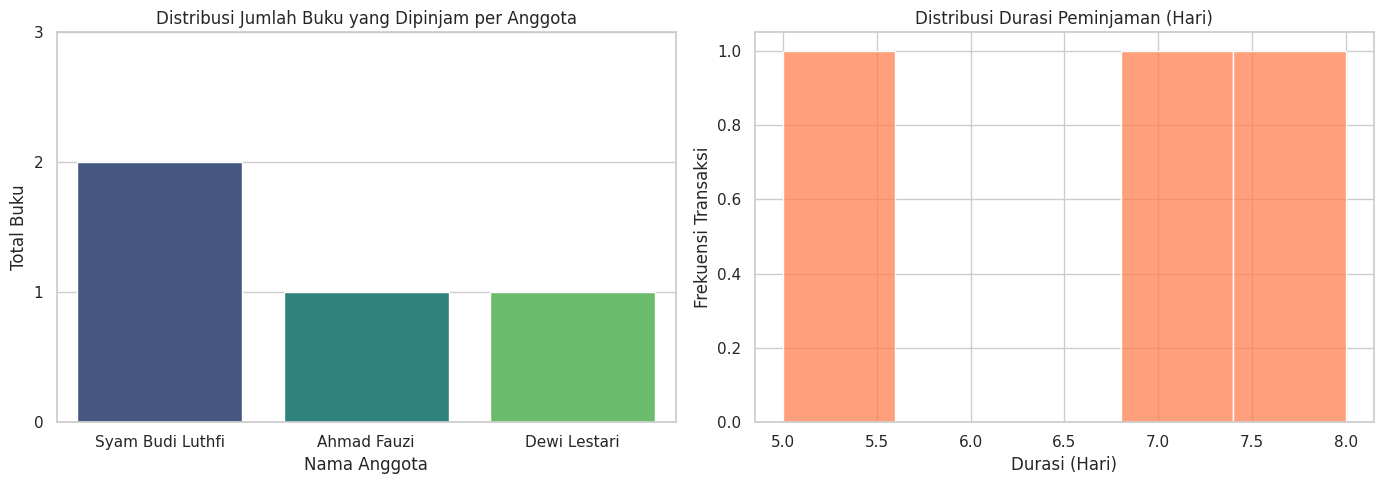

In [5]:
# 2c. Visualisasi Data

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Visualisasi 1: Diagram Batang (Jumlah Buku per Anggota)
sns.barplot(
    data=df_agregasi,
    x='Nama_Anggota',
    y='Total_Buku_Dipinjam',
    palette='viridis',
    ax=axes[0]
)
axes[0].set_title('Distribusi Jumlah Buku yang Dipinjam per Anggota', fontsize=12)
axes[0].set_xlabel('Nama Anggota')
axes[0].set_ylabel('Total Buku')
axes[0].set_yticks(range(0, max(df_agregasi['Total_Buku_Dipinjam'])+2)) # Agar sumbu Y bulat

# Visualisasi 2: Histogram (Distribusi Durasi Peminjaman)
# Kita drop (hapus sementara) nilai NaN untuk buku yang belum dikembalikan agar bisa diplot
sns.histplot(
    df_peminjaman['Durasi_Hari'].dropna(),
    bins=5,
    kde=False,
    color='coral',
    ax=axes[1]
)
axes[1].set_title('Distribusi Durasi Peminjaman (Hari)', fontsize=12)
axes[1].set_xlabel('Durasi (Hari)')
axes[1].set_ylabel('Frekuensi Transaksi')

plt.tight_layout()
plt.show()

# Menutup koneksi database karena tugas telah selesai
conn.close()